In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
llm=ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0
)

In [4]:
class subState(TypedDict):
    inputText:str
    translatedText:str


In [5]:
def translate_text(state:subState):
    input_text=state['inputText']
    prompt=f"As a helpful assistant translate the input into hindi:{input_text}"
    result=llm.invoke(prompt).content
    return {'translatedText':result}

In [12]:
graph=StateGraph(subState)
graph.add_node('translate_text',translate_text)

graph.add_edge(START,'translate_text')
graph.add_edge('translate_text',END)

workflow=graph.compile()

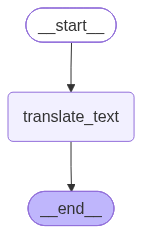

In [13]:
workflow

In [16]:
initial_input={
    'inputText':"Hello how are you"
}

result=workflow.invoke(initial_input)
result

{'inputText': 'Hello how are you', 'translatedText': 'नमस्ते, आप कैसे हैं?'}

In [19]:
class parentState(TypedDict):
    question:str
    answer_eng:str
    answer_hin:str

In [34]:
def answer_node(state:parentState):
    text=state['question']
    prompt=f"As a helpful assistant please answer this question :{text}"
    out=llm.invoke(prompt).content
    return {'answer_eng':out}

In [21]:
def translate_node(state:parentState):
    result=workflow.invoke({'inputText':state['answer_eng']})
    return {'answer_hin':result['translatedText']}


In [36]:
parent_graph=StateGraph(parentState)
parent_graph.add_node('answer_node',answer_node)
parent_graph.add_node('translate_node',translate_node)

parent_graph.add_edge(START,'answer_node')
parent_graph.add_edge('answer_node','translate_node')
parent_graph.add_edge('translate_node',END)

parent_workflow=parent_graph.compile()

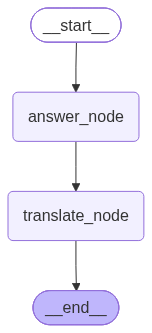

In [37]:
parent_workflow

In [39]:
initial_input_1={
    'question':'what is quantum physics?'
}
final_output=parent_workflow.invoke(initial_input_1)
final_output['answer_hin']


'ज़रूर, यहाँ आपके इनपुट का हिंदी अनुवाद है:\n\nक्वांटम भौतिकी, जिसे क्वांटम यांत्रिकी भी कहा जाता है, भौतिकी की एक मूलभूत शाखा है जो परमाणु और उप-परमाणु स्तरों पर पदार्थ और ऊर्जा के व्यवहार का वर्णन करती है। यह अनिवार्य रूप से बहुत, बहुत छोटे पैमाने की भौतिकी है।\n\nयहाँ एक विवरण दिया गया है कि क्या इसे इतना अनूठा और दिमाग घुमा देने वाला बनाता है:\n\n1.  **यह सबसे छोटी चीज़ों के बारे में है:** क्वांटम भौतिकी इलेक्ट्रॉन, प्रोटॉन, न्यूट्रॉन, फोटॉन (प्रकाश के कण) और इससे भी छोटे, अधिक विदेशी कणों जैसे कणों से संबंधित है। इस पैमाने पर, शास्त्रीय भौतिकी (वह भौतिकी जिसे हम अपनी रोजमर्रा की दुनिया में देखते हैं) के नियम बस लागू नहीं होते हैं।\n\n2.  **क्वांटाइज़ेशन (Quantization):** "क्वांटम" शब्द लैटिन शब्द से आया है जिसका अर्थ है "कितना"। एक मुख्य विचार यह है कि ऊर्जा, संवेग और कोणीय संवेग जैसे कुछ भौतिक गुण एक सतत स्पेक्ट्रम पर मौजूद नहीं होते हैं, बल्कि "क्वांटा" नामक असतत (अलग-अलग), अविभाज्य पैकेटों में होते हैं। इसे एक रैंप के बजाय एक सीढ़ी की तरह समझें – आप केवल विशिष्ट सीढ़ियों पर हो 